In [11]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from pathlib import Path
import datetime
import pickle
sys.path.insert(0, "./cellular_cycle")
sys.path.insert(0, "./figures")

from cell_cycle_death_model import model
from pysb.simulator import BngSimulator
from pysb.simulator import ScipyOdeSimulator
from model_fxns import *
from Cell_Population_Simulation import Cell_Population_Simulation
from SMs_G1s_IMTs_extraction import SMs_G1s_IMTs_extraction
import fracprolif as fp
from call_cell_events import call_events #
from retrieve_cellState_dw_2 import retrieve_cellState #

In [2]:
# Directory containing cell fate data
DATADIR = Path('../data/Exp_Intermitotic_Times/')

# Where to save large simulation output files
SAVE_DIR = Path(Path.home(),'ECM_mod_output')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

OVERWRITE = False # Overwrite existing simulation files

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

In [3]:
# import pysb sampled parameters
sampled_parameter_names = np.loadtxt(os.getcwd() + '/model_data/sampled_parameter_names.txt', dtype=str)

In [4]:
# Importing the parameters:
new_param = pd.read_csv(os.getcwd()+ '/model_data/parameters.csv')
for key in new_param.keys():
    try:
        if model.parameters[key].value != new_param[key][0]:
            model.parameters[key].value = new_param[key]
    except:
        print(key)
model.parameters['omega'].value = 200

In [5]:
# Setting initial concentrations '/../model_data/initial_concentrations.csv'
initial_concentrations = pd.read_csv(os.getcwd() + '/model_data/initial_concentrations.csv')
for key in initial_concentrations.keys():
    try:
        model.parameters[key].value = initial_concentrations[key][0] / model.parameters['omega'].value
    except:
        print(key)

In [6]:
# Import ECM_conditions.csv
ECM_conditions = pd.read_csv(os.getcwd() + '/model_data/ECM_conditions_2.csv')
ECM_conditions


,condition,stiffness,drug,species,value
0,55 kPa DMSO,55 kPa,DMSO,AKT,1.0
1,55 kPa DMSO,55 kPa,DMSO,ERK,1.0
2,55 kPa DMSO,55 kPa,DMSO,FAK,1.0
3,4 kPa DMSO,4 kPa,DMSO,AKT,1.0
4,4 kPa DMSO,4 kPa,DMSO,ERK,1.0
5,4 kPa DMSO,4 kPa,DMSO,FAK,0.6
6,0.6 kPa DMSO,0.6 kPa,DMSO,AKT,0.6
7,0.6 kPa DMSO,0.6 kPa,DMSO,ERK,1.0
8,0.6 kPa DMSO,0.6 kPa,DMSO,FAK,0.4
9,55 kPa erlotinib,55 kPa,erlotinib,AKT,0.6


2024-09-04 13:28:19.405 - pysb.simulator.scipyode - WARNING - [cell_cycle_death_model] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


<Axes: xlabel='Time (h)', ylabel='Concentration'>

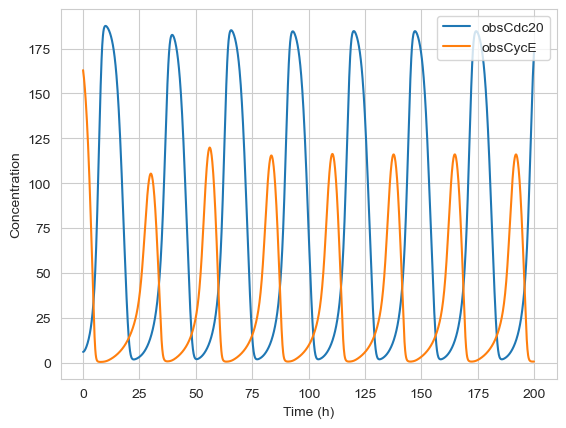

In [7]:
condition = "55 kPa erlotinib"

t = np.linspace(0, 20000, 200001)

model.parameters['AKT'].value = 0.6
model.parameters['ERK'].value = 0.2
model.parameters['FAK'].value = 1
# t = np.linspace(0, 50000, 500001)
sim_ode = ScipyOdeSimulator(model, t, verbose=False).run(); #deterministic simulation

observables=['obsCdc20', 'obsCycE']
plotObs(model=sim_ode.all, obs=observables, times=t, tpos=range(0,2000), legend=True)


<Axes: xlabel='Time (h)', ylabel='Concentration'>

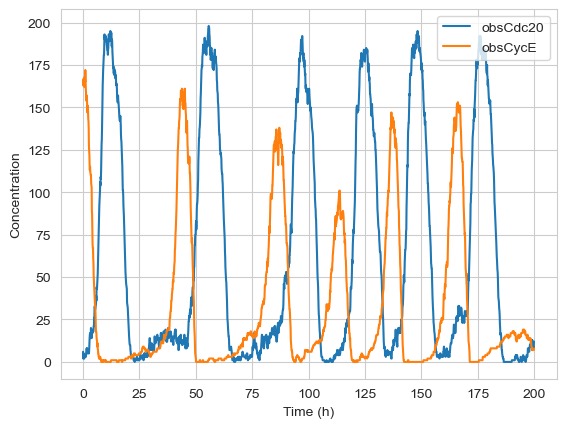

In [8]:
sim_stoch = BngSimulator(model, tspan=t, verbose=False)
sim_stoch_res = sim_stoch.run(method='ssa', verbose=False)
observables=['obsCdc20', 'obsCycE']
plotObs(model=sim_stoch_res.all, obs=observables, times=t, tpos=range(0,2000), legend=True)


In [9]:
start_time = datetime.datetime.now()

init = 5
run_time = 120
observed_cells_time = 120

In [10]:
# Run the model
# Simulate Check_Model_Consistency
# (variable_range, check, tmp_score) = Check_Model_Consistency(model, thr=0.26, return_plot=True)

(check, population_df, cells, cell_count) = Cell_Population_Simulation(init, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, thr=[0.26, 0.14], return_plot=False, bypass=True)
current_time = datetime.datetime.now()
print(f'elapsed time is {(current_time-start_time)/60} minutes')

55 kPa erlotinib
elapsed time is 0:00:02.047742 minutes


In [12]:
def plot_cell_count(cell_count, run_time, title="Unknown condition"):
    t_sim = np.arange(0, run_time, 1 / 3)
    cell_count_t = np.zeros(len(t_sim))
    time_tmp_m = 0
    for time_tmp_p, cell_count_time_tmp in cell_count:
        cell_count_t[(time_tmp_m <= t_sim) & (t_sim < time_tmp_p)] = cell_count_time_tmp
        time_tmp_m = time_tmp_p
    pop_dubs = np.log2(cell_count_t / cell_count_t[0])
    fig, ax = plt.subplots()
    ax.scatter(t_sim, pop_dubs, color="black", s=1)
    ax.set_xlabel('Time (h)')
    ax.set_ylabel('Population doublings')
    ax.set_ylim(0,5)
    plt.text(0,4.5,title)
    plt.show()

    return fig, ax

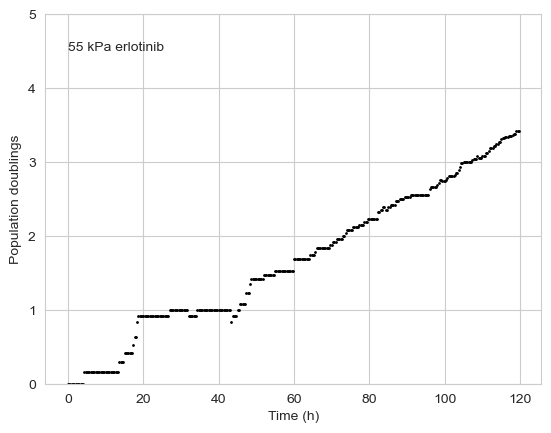

(<Figure size 640x480 with 1 Axes>,
 <Axes: xlabel='Time (h)', ylabel='Population doublings'>)

In [13]:
plot_cell_count(cell_count, run_time, title=condition)

(0.0, 125.0)

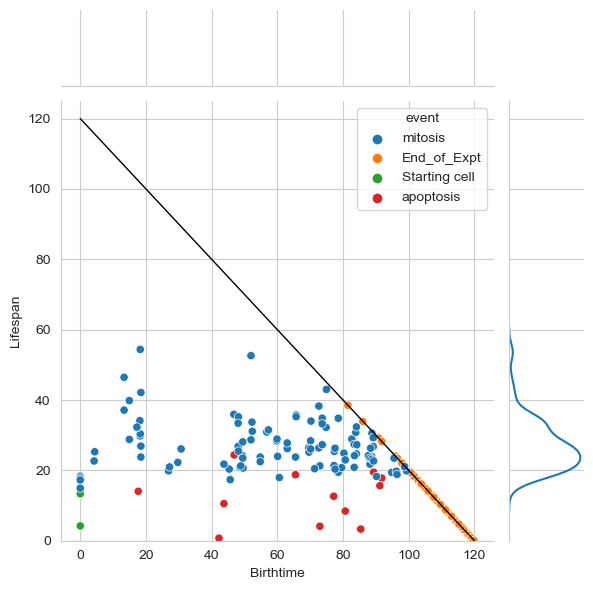

In [14]:
IMT_eoe_counts, all_prot = retrieve_cellState(run_time, cells, return_all_prot=True)
all_events_simulated = call_events(run_time, IMT_eoe_counts) #Gives all events (apoptosis, mitosis, quiescence) and when they happen

#plot the results
grid = sns.JointGrid(x='Birthtime', y='Lifespan', data=all_events_simulated) #x axis = birthtime of a cell, y = endtime of this cell
g = grid.plot_joint(sns.scatterplot, hue='event', data=all_events_simulated) 
g.ax_joint.plot([run_time, 0], [0, run_time], 'b-', linewidth = 1, color='black') #Recorded events behind this line
sns.kdeplot(all_events_simulated.loc[all_events_simulated['event']=='mitosis', 'Lifespan'].to_list(), 
            ax=g.ax_marg_y, vertical=True, legend=False, bw=0.3) #output distribution of intermitotic times
plt.ylim(0, 125)

In [18]:
def runIMTs(init, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, IMTs_count):
    all_IMTs = []
    n = 0
    while len(all_IMTs)<IMTs_count:
        check, population_df, cells, cell_count = Cell_Population_Simulation(init, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, thr=[0.26, 0.14], return_plot=False, bypass=True)
        IMT_eoe_counts, all_prot = retrieve_cellState(run_time, cells, return_all_prot=True)
        all_events_simulated = call_events(run_time, IMT_eoe_counts)
        
        mits = all_events_simulated.loc[all_events_simulated['event']=='mitosis'].reset_index()
        mits_list = mits['Lifespan'].tolist()
        mits_list_r = [round(x,1) for x in mits_list]

        IMT_tmp, s_m_tmp, g1_tmp = SMs_G1s_IMTs_extraction(cells)
        
        if n==0:
            all_IMTs = mits_list_r
            all_g1s = g1_tmp
        else:
            all_IMTs.extend(mits_list_r)
            all_g1s.extend(g1_tmp)
        
        # filename_cell_count = Path(SAVE_DIR, f'cell_counts_{condition}_{n}_cycdi_0_4.csv')
        # np.savetxt(filename_cell_count, cell_count, delimiter=',')
        
        n+=1
        print(len(all_IMTs))
        
    # filename_IMT = Path(SAVE_DIR, f'IMTs_{condition}_cycdi_500_0_4.csv')
    # filename_g1 = Path(SAVE_DIR, f'G1s_{condition}_cycdi_500_0_4.csv')
    # np.savetxt(filename_IMT, all_IMTs, delimiter=',')
    # np.savetxt(filename_g1, all_g1s, delimiter=',')
    return all_IMTs, all_g1s

In [22]:
condition = "55 kPa erlotinib"

In [23]:
model.parameters['AKT'].value = 0.6
model.parameters['ERK'].value = 0.2
model.parameters['FAK'].value = 1
model.parameters['CycDi_0'].value = 0.4

In [24]:
all_IMTs, all_g1s = runIMTs(10, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, 100)

55 kPa erlotinib


IndexError: list index out of range

In [20]:
all_IMTs

[15.9,
 48.8,
 32.6,
 25.4,
 25.6,
 23.0,
 36.1,
 17.9,
 23.9,
 21.3,
 25.3,
 20.0,
 27.1,
 24.5,
 26.8,
 31.0,
 19.7,
 42.5,
 24.0,
 25.7,
 28.0,
 23.1,
 36.1,
 28.7,
 15.4,
 53.7,
 25.3,
 22.8,
 26.0,
 21.5,
 45.3,
 33.9,
 26.7,
 22.5,
 26.1,
 28.2,
 27.5,
 16.8,
 20.3,
 31.0,
 22.0,
 42.3,
 21.0,
 26.9,
 34.8,
 34.7,
 21.1,
 27.9,
 40.7,
 19.9,
 27.2,
 55.7,
 22.1,
 25.6,
 52.2,
 28.8,
 45.9,
 28.1,
 25.8,
 27.6,
 31.1,
 20.4,
 29.7,
 16.5,
 35.0,
 25.6,
 29.1,
 28.6,
 28.7,
 19.5,
 22.6,
 58.0,
 32.4,
 22.9,
 29.6,
 22.6,
 23.8,
 26.4,
 26.8,
 17.0,
 60.3,
 21.2,
 21.5,
 24.9,
 31.5,
 22.7,
 55.3,
 25.3,
 36.5,
 22.1,
 24.2,
 28.6,
 27.2,
 34.3,
 29.9,
 27.6,
 19.4,
 24.8,
 26.8,
 29.7,
 26.0,
 24.5,
 29.8,
 26.1,
 22.9,
 22.3,
 26.8,
 22.2,
 24.2,
 25.7,
 26.4,
 28.7,
 33.3,
 29.3,
 22.2,
 24.1,
 25.9,
 28.7,
 19.2,
 26.2,
 29.3,
 29.2,
 19.5,
 30.4,
 29.9,
 19.5,
 31.1,
 30.4,
 24.8,
 25.4,
 21.4,
 23.1,
 21.0,
 31.3,
 30.7,
 21.6,
 17.4,
 25.1,
 21.7,
 29.7,
 17.3,
 30.6,
 23.4,